# Recommendation evaluation: natural requests and catalog constraints

**72 individually authored naturalistic requests; 48 use indirect wording.**
Topics include mood and tags, genres, release years and full dates, animation studios,
formats, adaptation source, episode counts, episode runtime, and combined constraints.
These are synthetic examples of user questions, **not collected user logs**.

The actual RAG answers each question. A **separate schema-constrained LLM request**
extracts recommended titles in order. Deterministic code resolves title aliases and
scores every recommendation against frozen catalog attributes. Neither the RAG nor
the extractor receives the reference labels. This notebook defaults to offline
inspection and displays saved live results when available.

The selected result is the **complete 72-request model run**, not a smoke subset.
Scores were recomputed against the current reference/policy from saved genuine
model answers and LLM title extractions; generation errors remain part of that run.
Use a new run name with `RUN_LIVE = True` to measure a fresh pipeline version.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/recommendation_evaluation.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebook folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.recommendation_evaluation import Catalog, load_dataset, METRICS
from src.config import load_settings

DATA = ROOT / 'data/evaluation/recommendations'
PYTHON = ROOT / '.venv' / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
if not PYTHON.is_file():
    PYTHON = Path(sys.executable)  # offline inspection can use the notebook kernel's environment
REFERENCE_AVAILABLE = (DATA / 'catalog_reference.jsonl').is_file()
questions, catalog, manifest = load_dataset(DATA, require_catalog=REFERENCE_AVAILABLE)
frame = pd.DataFrame(questions)
SETTINGS = load_settings(ROOT / 'settings.toml', 'anilist')
print(f'{len(questions)} questions | {frame.category.nunique()} categories')
if REFERENCE_AVAILABLE:
    print(f'{len(catalog.records)} local catalog references; all reference hashes verified.')
else:
    print('Authored question/policy hashes verified. Bulk catalog is not needed for offline coverage.')
    print('For live scoring: complete AniList setup, then run python scripts/build_recommendation_benchmark.py.')
print('No database mutation, inference, or downloads.')

72 questions | 11 categories
20428 local catalog references; all reference hashes verified.
No database mutation, inference, or downloads.


## Labels and coverage

Each request specifies its desired count `k` and a list of expected constraints.
Constraints use `any`, `all`, `none`, `gte`, `lte`, or `eq`. All listed constraints
must hold for a strict match. Alternative acceptable tags can share one `any` group.
For example, “something comforting after work” can be supported by **Iyashikei**, or
an annotated combination of everyday-life genre/themes without a strong tragic theme.
An investigation request accepts **Detective OR Mystery**, across tags and genres.
**32 requests have reviewed alternative evidence paths**. Every catalog tag is retained
in the reference (422 in this snapshot), rather than freezing only the original target tags.

Alternative paths are written per request in `semantic_policy.json`, with rationales.
Each path can require several supporting conditions together. Unrelated extra tags
never reduce a score. Precise requests such as “carry the Detective tag” retain that
literal requirement; broader clue-solving requests accept Mystery. Exclusions and
dates, studios, counts, and other independent requirements still apply. These are
reviewable annotation choices, not universal synonym rules or a guarantee of mood.

Indirect studio requests include identifying the studio behind another named anime.
Dates refer to the first release of the specific recommended entry. Studios must be
flagged as both main and animation studios. Missing scalar metadata fails its constraint.

In [2]:
display(pd.crosstab(frame.category, frame.wording).assign(total=lambda t: t.sum(axis=1)))
display(frame.groupby('category', sort=False).head(1)[
    ['question_id', 'question', 'k', 'constraints', 'strict_catalog_matches']])
display(frame[frame.wording.eq('indirect')].sample(6, random_state=7)[
    ['question', 'constraints', 'label_rationale']])
assert frame.question_id.is_unique and frame.question.str.casefold().is_unique
assert frame.question_origin.eq('authored_naturalistic').all()
print('Dataset provenance:', manifest['origin'])

wording,explicit,indirect,total
category,,,
formats,2,4,6
genres,4,8,12
length,2,4,6
mixed_constraints,1,2,3
multiple_tags,1,2,3
release_date,1,2,3
release_year,2,4,6
source_material,1,2,3
studios,2,4,6


,question_id,question,k,constraints,strict_catalog_matches
0,comfort_01,Can you recommend three iyashikei anime for wi...,3,"[{'field': 'tags', 'op': 'any', 'value': ['Iya...",867
21,space_military_01,Recommend three anime with both Space and Mili...,3,"[{'field': 'tags', 'op': 'any', 'value': ['Spa...",196
24,comfort_exclusion_01,Give me three iyashikei recommendations withou...,3,"[{'field': 'tags', 'op': 'any', 'value': ['Iya...",844
27,fantasy_01,Recommend three anime in the fantasy genre.,3,"[{'field': 'genres', 'op': 'any', 'value': ['F...",5157
39,recent_01,Recommend three anime first released in 2020 o...,3,"[{'field': 'year', 'op': 'gte', 'value': 2020}]",5100
45,dates_01,Recommend three anime with a first release dat...,3,"[{'field': 'start_date', 'op': 'gte', 'value':...",1505
48,kyoani_01,Which three anime made by Kyoto Animation woul...,3,"[{'field': 'studios', 'op': 'any', 'value': ['...",119
54,movies_01,Recommend three anime movies.,3,"[{'field': 'format', 'op': 'any', 'value': ['M...",3268
60,manga_01,Recommend three anime adapted from manga.,3,"[{'field': 'source_material', 'op': 'any', 'va...",5246
63,short_series_01,Recommend three TV anime with at most 12 episo...,3,"[{'field': 'format', 'op': 'any', 'value': ['T...",1745


,question,constraints,label_rationale
20,I want five anime where following clues and fi...,"[{'field': 'tags', 'op': 'any', 'value': ['Det...",A central investigator solving cases maps to D...
23,I would like five anime about organized fleets...,"[{'field': 'tags', 'op': 'any', 'value': ['Spa...",Both space setting and military organization m...
34,Which four anime would make a good lights-off ...,"[{'field': 'genres', 'op': 'any', 'value': ['H...","Frightening viewing maps to Horror, not every ..."
55,I do not want to start a series. What are four...,"[{'field': 'format', 'op': 'any', 'value': ['M...",Movie format only; no runtime cap is implied.
61,What are four anime that began as Japanese com...,"[{'field': 'source_material', 'op': 'any', 'va...",MANGA source medium is required; popularity or...
37,What are four anime where making the audience ...,"[{'field': 'genres', 'op': 'any', 'value': ['C...",The broad request to laugh maps to Comedy rath...


Dataset provenance: Individually authored naturalistic synthetic English requests; not real user logs.


## Catalog evidence for accepted implications

This uses real catalog entries to compare Mystery without a strong Detective tag
under an exact tag request and the broader investigation request. If the local
reference has not been rebuilt, this section reports that prerequisite; it does not
substitute synthetic records or model results.

In [3]:
lookup = {q['question_id']: q for q in questions}
implication_examples = []
if catalog is None:
    records = []
    print('Real catalog examples require AniList setup and the reference build. No substitute records are used.')
else:
    records = catalog.records.values()
for record in records:
    if 'Mystery' in record['genres'] and record['tag_ranks'].get('Detective', 0) < 50:
        implication_examples.append({
            'title': record['title'], 'Detective rank': record['tag_ranks'].get('Detective', 0),
            'Mystery genre': True,
            'explicit tag request': Catalog.fits(lookup['detectives_01'], record)[1],
            'investigation request': Catalog.fits(lookup['detectives_02'], record)[1]})
    if len(implication_examples) == 5:
        break
display(pd.DataFrame(implication_examples))
print('Accepted alternatives:', manifest['requests_with_alternatives'], 'requests')

,title,Detective rank,Mystery genre,explicit tag request,investigation request
0,KOKKOKU,0,True,0,1
1,Attack on Titan: The Roar of Awakening,0,True,0,1
2,We Rent Tsukumogami,0,True,0,1
3,Caligula,0,True,0,1
4,Made in Abyss: Dawn of the Deep Soul,0,True,0,1


Accepted alternatives: 32 requests


## Metric definitions

For a tag constraint, the graded value is its catalog relevance rank divided by 100;
`any` takes the maximum, `all` the minimum, and `none` one minus the maximum.
Other constraints score 0 or 1. A recommendation's **graded fit** is their equal-weight
mean. Each intent takes the best score across its literal path and reviewed alternatives;
an alternative's score is the minimum of its supporting condition scores. **Strict match**
requires a passing path for every intent. Positive tag ranks must reach 50, excluded
tags stay below 50, and all non-tag conditions in that path must pass.

| Metric | Definition |
| --- | --- |
| Strict P@k | Unique, resolved, fully compliant recommendations in the first k positions / requested k |
| Literal P@k | The same computation using only the original direct labels, for comparison |
| Semantic credit@k | Fraction of requested slots rescued by an accepted alternative |
| Graded fit@k | Sum of mean constraint fits in those positions / k |
| nDCG@k | Rank-discounted graded fit / ideal fit from the best k unique entries in the entire frozen catalog |
| Constraint coverage | Fraction of expected constraints met by at least one top-k recommendation; different items may meet different constraints |
| Count compliance | Extracted list length equals requested k |
| Resolution / duplicate rates | Fractions across all returned recommendations, including extras |

Missing positions, unknown titles, ambiguous aliases, and duplicate entries contribute
zero to P@k and graded/ranking gains. Recommendations beyond k are still audited and
counted as extras. nDCG uses linear gains and log2 discounts. It measures ranking of
catalog fit, not subjective quality or catalog-recall. End-to-end P@k includes all
attempted requests, with model errors and unclear parses contributing zero. Conditional
scored-only metrics and scoring coverage are shown separately. Unattempted requests
are pending and excluded from performance denominators.

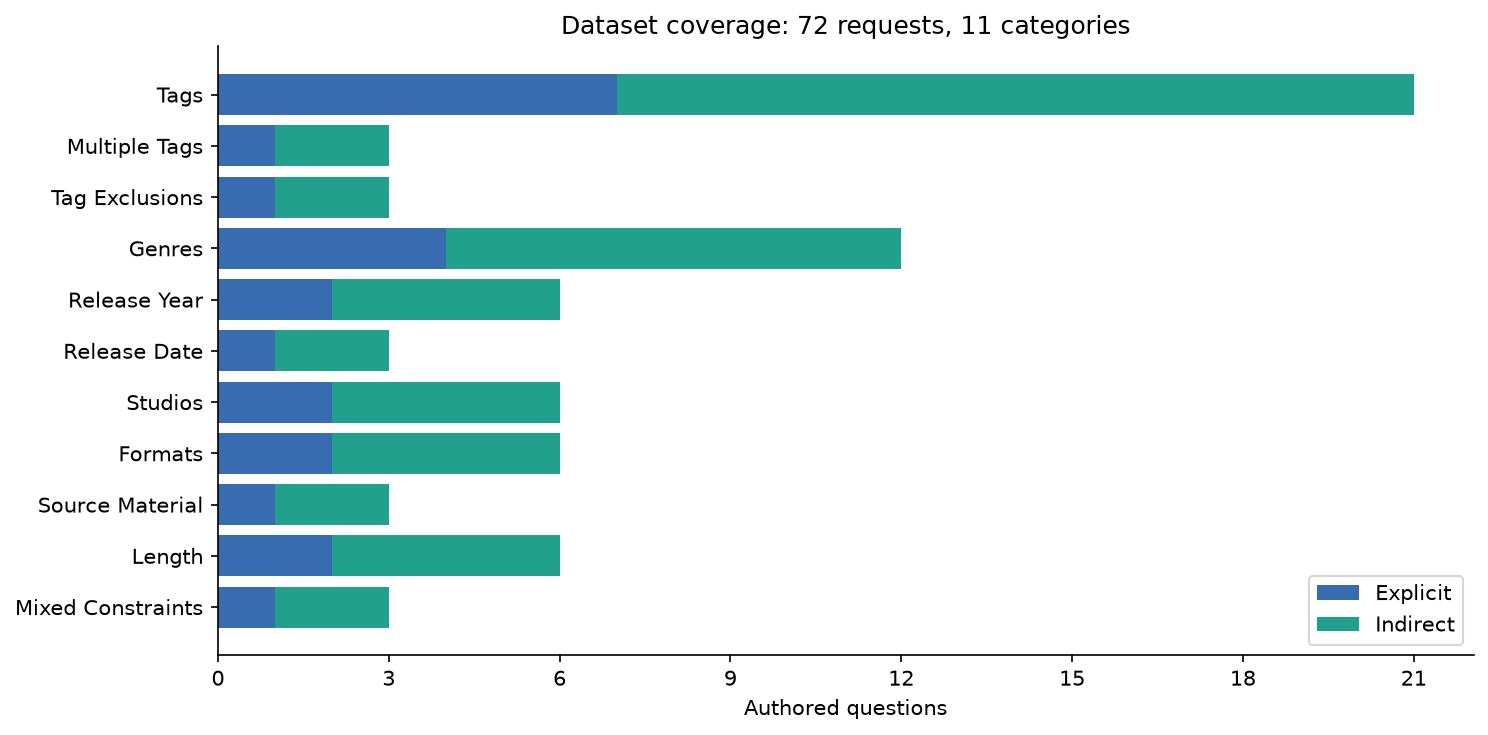

Complete dataset. Indirect wording describes a preference without naming every expected catalog label.
PNG and SVG exports: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\recommendations\charts


In [4]:
def show_charts(results=None):
    output = Path(results) / 'charts' if results is not None else DATA / 'charts'
    command = [str(PYTHON), '-X', 'utf8', '-m', 'src.recommendation_visualizations',
               '--dataset', str(DATA), '--output', str(output)]
    if results is not None:
        command += ['--results', str(results)]
    completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                               encoding='utf-8', errors='replace', env={**os.environ, 'MPLBACKEND': 'Agg'})
    if completed.returncode:
        raise RuntimeError('Chart rendering failed. Install uv sync --extra evaluation. ' + completed.stderr)
    artifacts = json.loads((output / 'charts.json').read_text(encoding='utf-8'))
    for artifact in artifacts:
        if results is not None and Path(artifact['png']).stem == 'dataset_coverage':
            continue
        display(Image(filename=artifact['png']))
        print(artifact['caption'])
    print('PNG and SVG exports:', output)

show_charts()

## Run the actual model

This notebook selects **all 72 requests**. `RUN_LIVE = False` displays the completed
full run when available; set it to `True` to run or resume full live inference.
Use a new `RUN_NAME` for a new model,
new extraction model, changed settings, or a retry of a failed question. Identical
runs resume per-question checkpoints, including failures. `MAX_NEW_QUESTIONS` limits
new attempts per execution without changing the selection; `None` continues all.

The prepared AniList indexes and Ollama model must already be available. Live inference
runs in the project's interpreter to isolate it from conflicting notebook dependencies.
Every question starts with empty history and fresh agent state. Extraction transcribes
only positively recommended titles, excluding comparisons and rejected suggestions.
It preserves duplicates and order. Failed JSON validation is retried once; uncertain
extraction is marked for review. LLM extraction cannot guarantee error-free parsing.

In [5]:
RUN_LIVE = False
MODE = 'full'                   # all 72 questions; no smoke subset in this notebook
RUN_NAME = 'full_real_v2'        # full real responses, rescored against the current reference/policy
EXTRACTOR_MODEL = None          # e.g. a separately installed stronger Ollama model
MAX_NEW_QUESTIONS = None        # 0 loads checkpoints only; None continues remaining requests

if MODE != 'full':
    raise ValueError('This notebook evaluates the full 72-request benchmark.')
if not RUN_NAME or Path(RUN_NAME).name != RUN_NAME or RUN_NAME in {'.', '..'}:
    raise ValueError('RUN_NAME must be a single directory name')
OUTPUT = DATA / 'results' / RUN_NAME
print('Generation:', SETTINGS.llm, '| Extraction:', EXTRACTOR_MODEL or SETTINGS.llm)
print('Mode:', MODE, '| Live inference:', RUN_LIVE, '| Output:', OUTPUT)

Generation: llama3.2:3b | Extraction: llama3.2:3b
Mode: full | Live inference: False | Output: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\recommendations\results\full_real_v2


In [6]:
if RUN_LIVE:
    if not REFERENCE_AVAILABLE or not (SETTINGS.documents / 'catalog.sqlite3').is_file():
        raise RuntimeError('Live scoring needs AniList setup and python scripts/build_recommendation_benchmark.py. Offline inspection works without those files.')
    command = [str(PYTHON), '-u', '-X', 'utf8', '-m', 'src.recommendation_evaluation',
               '--settings', str(ROOT / 'settings.toml'), '--dataset', str(DATA),
               '--output', str(OUTPUT), '--mode', MODE]
    if EXTRACTOR_MODEL:
        command += ['--extractor-model', EXTRACTOR_MODEL]
    if MAX_NEW_QUESTIONS is not None:
        command += ['--max-new-questions', str(MAX_NEW_QUESTIONS)]
    process = subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding='utf-8', errors='replace',
                               env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait():
            raise RuntimeError('Evaluation failed. See subprocess output above.')
    except BaseException:
        process.terminate()
        process.wait()
        raise
else:
    print('Offline inspection. Set RUN_LIVE = True to generate new answers.')

Offline inspection. Set RUN_LIVE = True to generate new answers.


## Saved results and recommendation-level audit

Partial results are explicitly labeled. The audit table includes every extracted
recommendation, its canonical identity, resolution status, duplicate flag, and each
constraint score. Inspect the original answer alongside extraction whenever a title
is missing, ambiguous, or unexpectedly included. Reference examples in the dataset
are illustrative, not an exhaustive acceptable recommendation list.

In [7]:
rows = []
if (OUTPUT / 'answers.json').is_file():
    saved_manifest = json.loads((OUTPUT / 'manifest.json').read_text(encoding='utf-8'))
    if saved_manifest['mode'] != 'full' or saved_manifest['question_ids'] != [q['question_id'] for q in questions]:
        raise ValueError('Select a real full-benchmark run; subset results are not accepted here.')
    report = json.loads((OUTPUT / 'metrics.json').read_text(encoding='utf-8'))
    rows = json.loads((OUTPUT / 'answers.json').read_text(encoding='utf-8'))
    overall = report['overall']
    print(f"Attempted {overall['attempted']}/{overall['planned']} selected requests; {overall['pending']} pending.")
    print(f"Full benchmark has {len(questions)} requests. This is {'a full benchmark' if len(rows) == len(questions) else 'a partial benchmark' }.")
    display(pd.DataFrame([{k: v for k, v in overall.items() if k not in {'scored_macro', 'status_counts'}}]))
    display(pd.DataFrame([overall['scored_macro']]).rename(index={0: 'scored-only macro'}))
    summaries = []
    for category, summary in report['by_category'].items():
        if summary['attempted']:
            summaries.append({'category': category, 'n': summary['attempted'],
                              'end_to_end_P@k': summary['end_to_end_precision_at_k'],
                              'scoring_coverage': summary['scoring_coverage'], **summary['scored_macro']})
    display(pd.DataFrame(summaries))
    audit = [{**d, 'question_id': r['question_id']} for r in rows for d in r['recommendations']]
    if audit:
        display(pd.DataFrame(audit)[['question_id', 'rank', 'extracted_title', 'canonical_title',
                                     'resolution', 'duplicate', 'constraint_scores', 'raw_fit', 'strict_match']])
        evidence_audit = [{'question_id': r['question_id'], 'rank': d['rank'],
                           'title': d['extracted_title'], 'constraint_index': i,
                           'literal_score': e['literal_score'], 'accepted_score': e['score'],
                           'credited_path': e['credited_path'], 'paths': e['paths']}
                          for r in rows for d in r['recommendations']
                          for i, e in enumerate(d.get('constraint_evidence', []))]
        display(pd.DataFrame(evidence_audit).head(15))
    else:
        print('No resolved extraction audits yet. Inspect errors below.')
else:
    print('No saved run yet. Dataset coverage is available above; model scores require RUN_LIVE = True.')

Attempted 72/72 selected requests; 0 pending.
Full benchmark has 72 requests. This is a full benchmark.


,planned,attempted,pending,scored,scoring_coverage,end_to_end_precision_at_k
0,72,72,0,61,0.847222,0.481481


,precision_at_k,graded_fit_at_k,ndcg_at_k,constraint_coverage,count_compliance,resolution_rate,duplicate_rate,extra_count,literal_precision_at_k,semantic_credit_at_k
scored-only macro,0.568306,0.607102,0.614892,0.806011,0.344262,0.921311,0.016393,1.147541,0.546995,0.021311


,category,n,end_to_end_P@k,scoring_coverage,precision_at_k,graded_fit_at_k,ndcg_at_k,constraint_coverage,count_compliance,resolution_rate,duplicate_rate,extra_count,literal_precision_at_k,semantic_credit_at_k
0,formats,6,0.611111,0.666667,0.916667,0.916667,0.925980,1.000000,0.250000,0.950000,0.000000,1.250000,0.916667,0.000000
1,genres,12,0.788889,1.000000,0.788889,0.782222,0.815000,1.000000,0.333333,0.883333,0.041667,1.416667,0.772222,0.016667
2,length,6,0.444444,0.666667,0.666667,0.766667,0.736483,0.875000,0.500000,0.900000,0.000000,1.000000,0.666667,0.000000
3,mixed_constraints,3,0.333333,0.666667,0.500000,0.765333,0.780035,0.833333,0.500000,1.000000,0.000000,1.000000,0.500000,0.000000
4,multiple_tags,3,0.133333,1.000000,0.133333,0.469472,0.510886,0.666667,0.666667,1.000000,0.000000,0.666667,0.133333,0.000000
5,release_date,3,0.333333,0.333333,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.500000,6.000000,1.000000,0.000000
6,release_year,6,0.300000,1.000000,0.300000,0.522222,0.507253,0.583333,0.333333,0.900000,0.000000,1.000000,0.300000,0.000000
7,source_material,3,0.666667,1.000000,0.666667,0.666667,0.666667,0.666667,0.000000,1.000000,0.000000,1.000000,0.666667,0.000000
8,studios,6,0.166667,0.500000,0.333333,0.333333,0.333333,0.333333,0.000000,1.000000,0.000000,1.333333,0.333333,0.000000
9,tag_exclusions,3,0.400000,1.000000,0.400000,0.588333,0.563117,0.833333,0.666667,0.933333,0.000000,0.666667,0.333333,0.066667


,question_id,rank,extracted_title,canonical_title,resolution,duplicate,constraint_scores,raw_fit,strict_match
0,comfort_01,1,Frieren: Beyond Journey’s End,Frieren: Beyond Journey’s End,resolved,False,[0.63],0.630000,1
1,comfort_01,2,The Fragrant Flower Blooms With Dignity,The Fragrant Flower Blooms With Dignity,resolved,False,[0.82],0.820000,1
2,comfort_01,3,March comes in like a lion,March comes in like a lion,resolved,False,[0.46],0.460000,0
3,comfort_01,4,March comes in like a lion Season 2,March comes in like a lion Season 2,resolved,False,[0.64],0.640000,1
4,comfort_01,5,Girls' Last Tour,Girls' Last Tour,resolved,False,[0.86],0.860000,1
...,...,...,...,...,...,...,...,...,...
304,mixed_03,1,That Time I Got Reincarnated as a Slime the Mo...,That Time I Got Reincarnated as a Slime the Mo...,resolved,False,"[1.0, 1.0, 0.0]",0.666667,0
305,mixed_03,2,BELLE,BELLE,resolved,False,"[0.46, 1.0, 0.0]",0.486667,0
306,mixed_03,3,WONDER EGG PRIORITY,WONDER EGG PRIORITY,resolved,False,"[1.0, 1.0, 0.0]",0.666667,0
307,mixed_03,4,Fena: Pirate Princess,Fena: Pirate Princess,resolved,False,"[0.5, 1.0, 0.0]",0.500000,0


,question_id,rank,title,constraint_index,literal_score,accepted_score,credited_path,paths
0,comfort_01,1,Frieren: Beyond Journey’s End,0,0.63,0.63,literal,"[{'path': 'literal', 'score': 0.63, 'met': Tru..."
1,comfort_01,2,The Fragrant Flower Blooms With Dignity,0,0.82,0.82,literal,"[{'path': 'literal', 'score': 0.82, 'met': Tru..."
2,comfort_01,3,March comes in like a lion,0,0.46,0.46,literal,"[{'path': 'literal', 'score': 0.46, 'met': Fal..."
3,comfort_01,4,March comes in like a lion Season 2,0,0.64,0.64,literal,"[{'path': 'literal', 'score': 0.64, 'met': Tru..."
4,comfort_01,5,Girls' Last Tour,0,0.86,0.86,literal,"[{'path': 'literal', 'score': 0.86, 'met': Tru..."
5,comfort_02,1,The Promised Neverland,0,0.00,0.00,literal,"[{'path': 'literal', 'score': 0.0, 'met': Fals..."
6,comfort_02,2,Dr. STONE,0,0.00,0.00,literal,"[{'path': 'literal', 'score': 0.0, 'met': Fals..."
7,comfort_02,3,JUJUTSU KAISEN,0,0.00,0.00,literal,"[{'path': 'literal', 'score': 0.0, 'met': Fals..."
8,comfort_02,4,Your lie in April,0,0.00,0.00,literal,"[{'path': 'literal', 'score': 0.0, 'met': Fals..."
9,comfort_02,5,A Silent Voice,0,0.00,0.00,literal,"[{'path': 'literal', 'score': 0.0, 'met': Fals..."


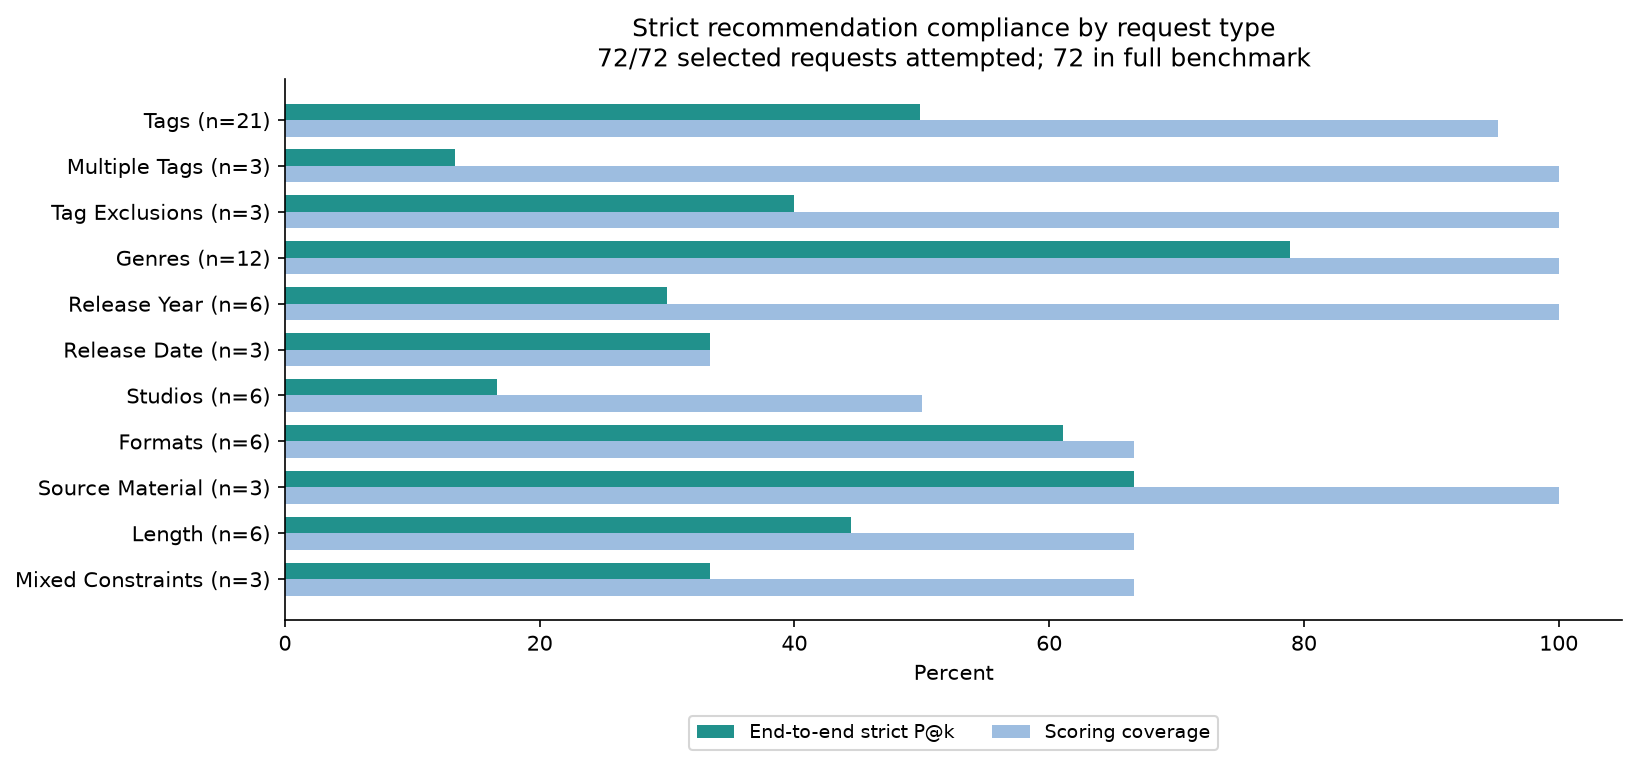

Each recommendation must meet every constraint. Missing slots, unresolved titles, and duplicates score zero. Errors remain in the end-to-end denominator.


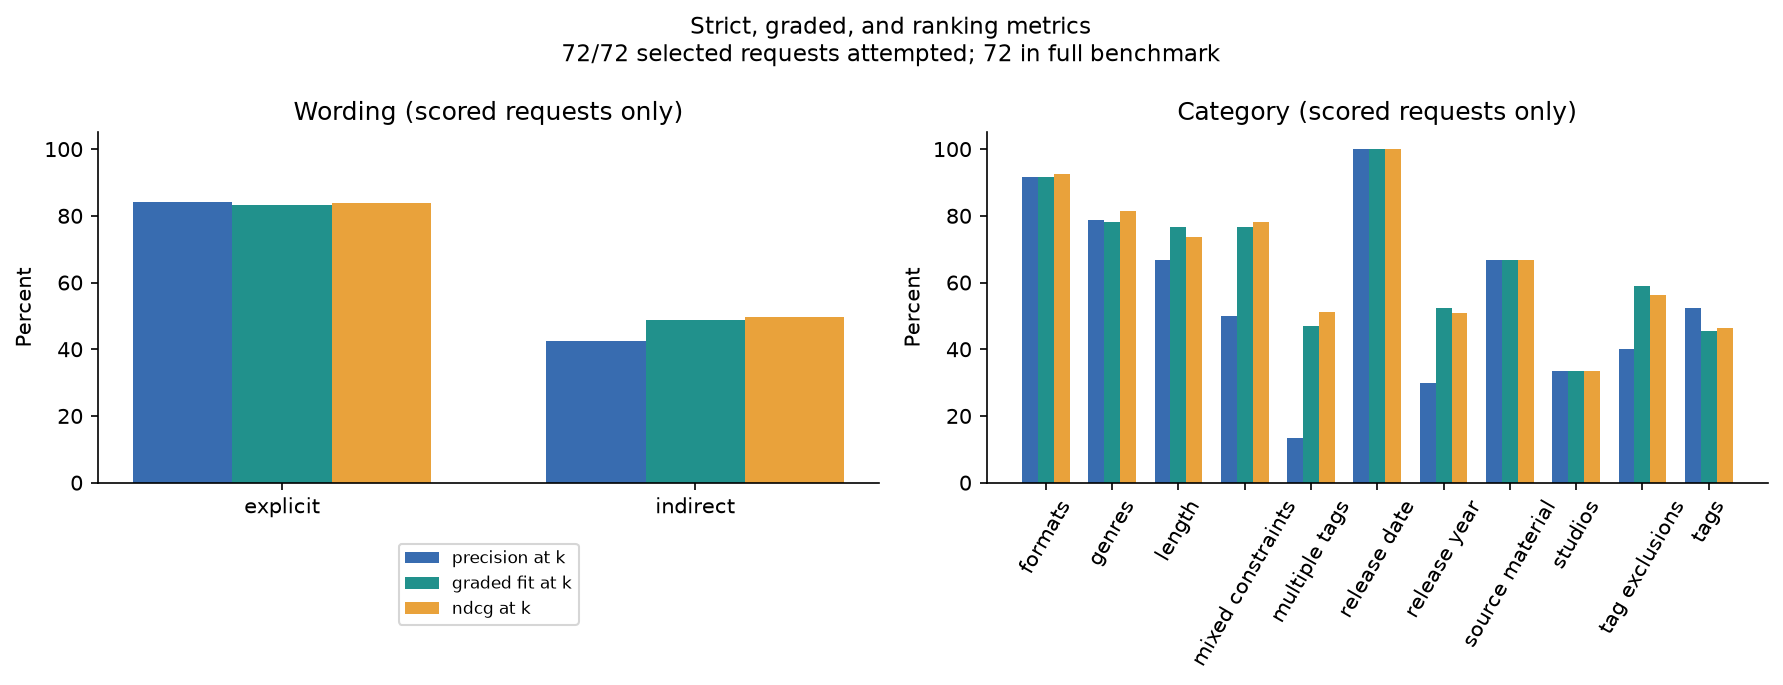

Scored-answer macro averages. Missing scores have no bar. nDCG uses the best possible unique catalog matches for each specific request, not a fixed hand-picked list.


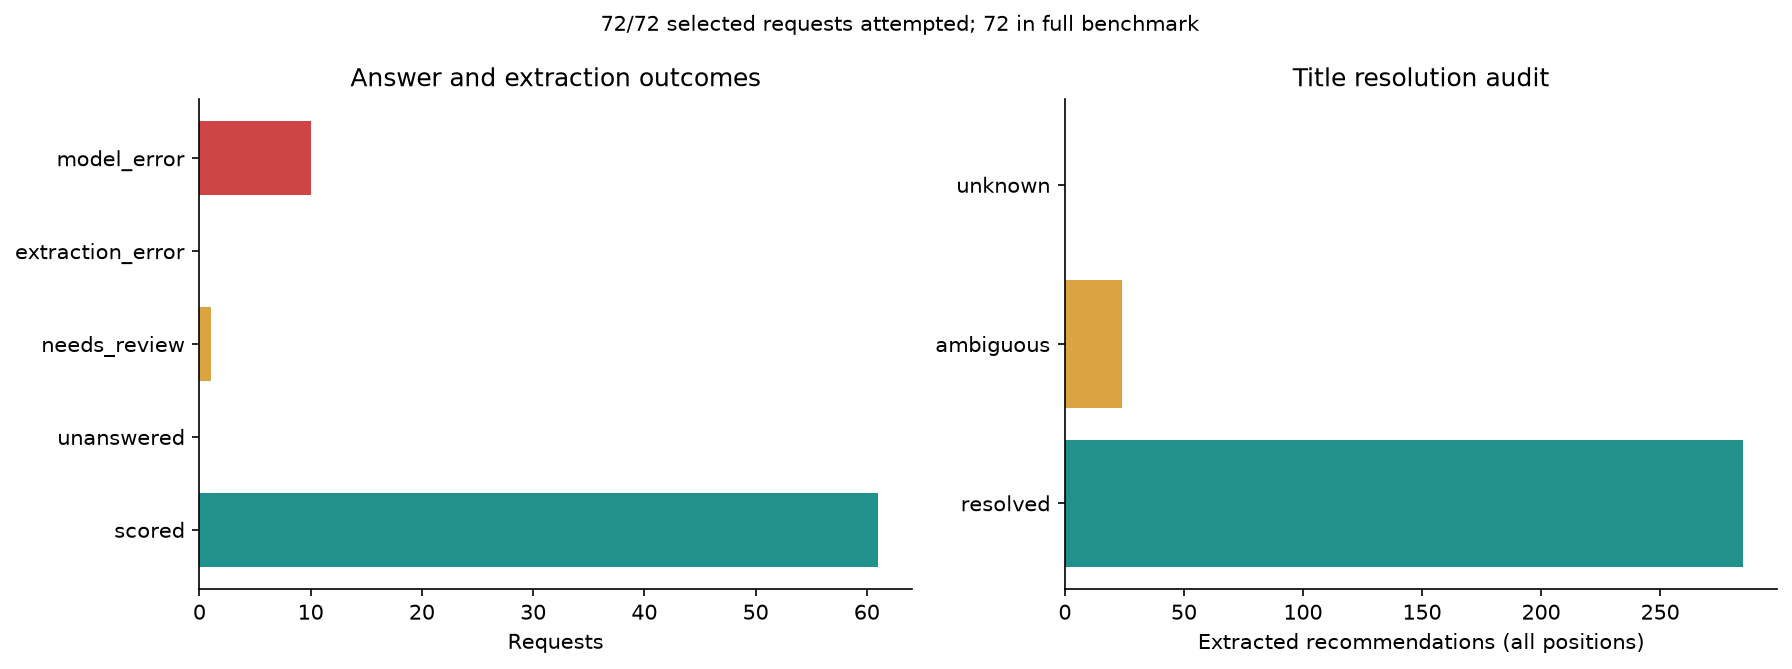

LLM extraction is fallible: uncertain parses are held for review. Ambiguous or out-of-catalog names never receive a guessed title identity.


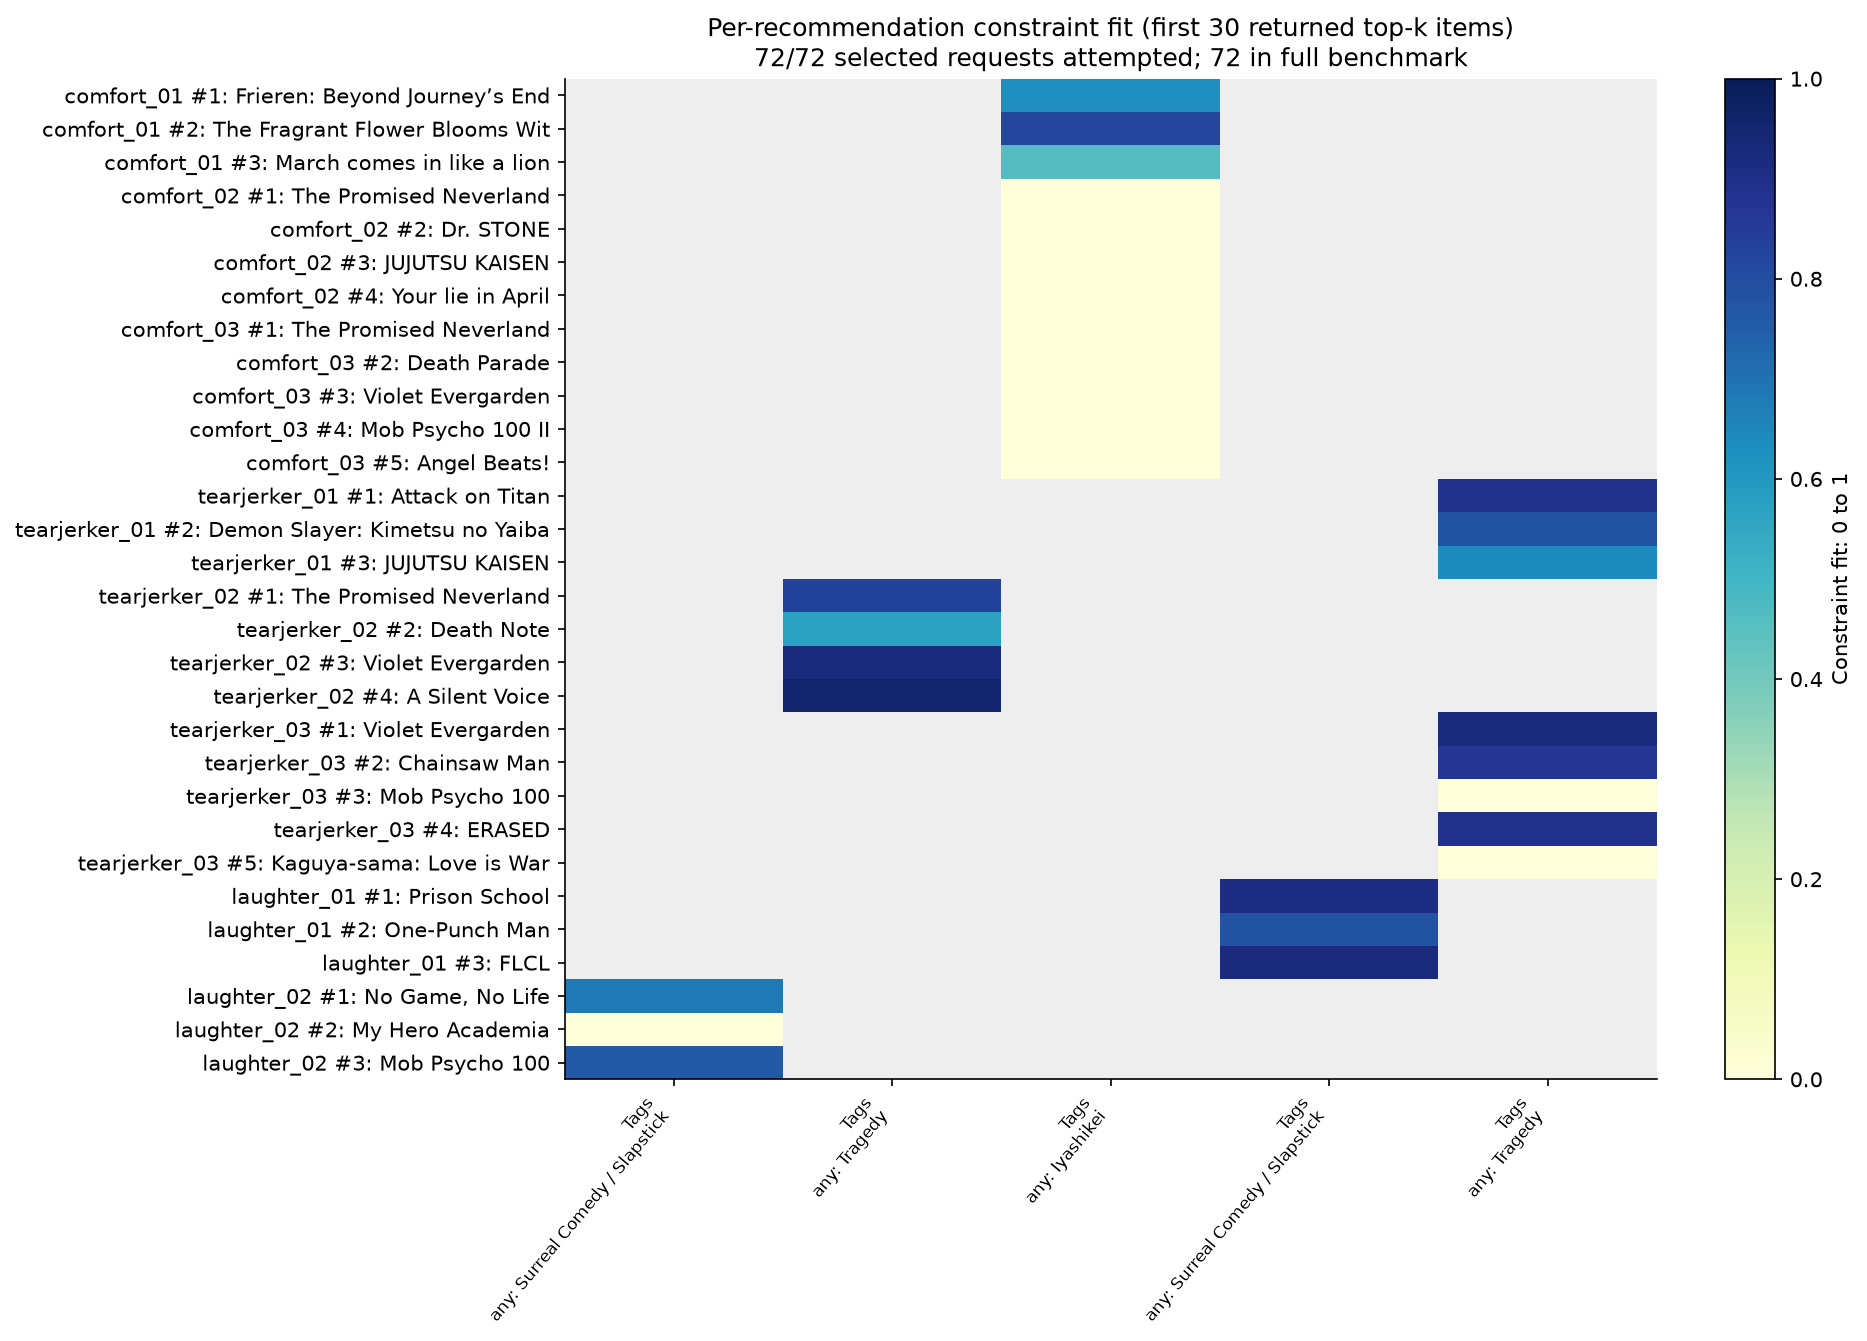

Each column is an individual expected constraint, including each required or excluded tag group. Gray means it was not requested for that item. Duplicate flags and identities are in recommendations.csv. Missing slots are excluded from this audit heatmap but penalized in P@k.


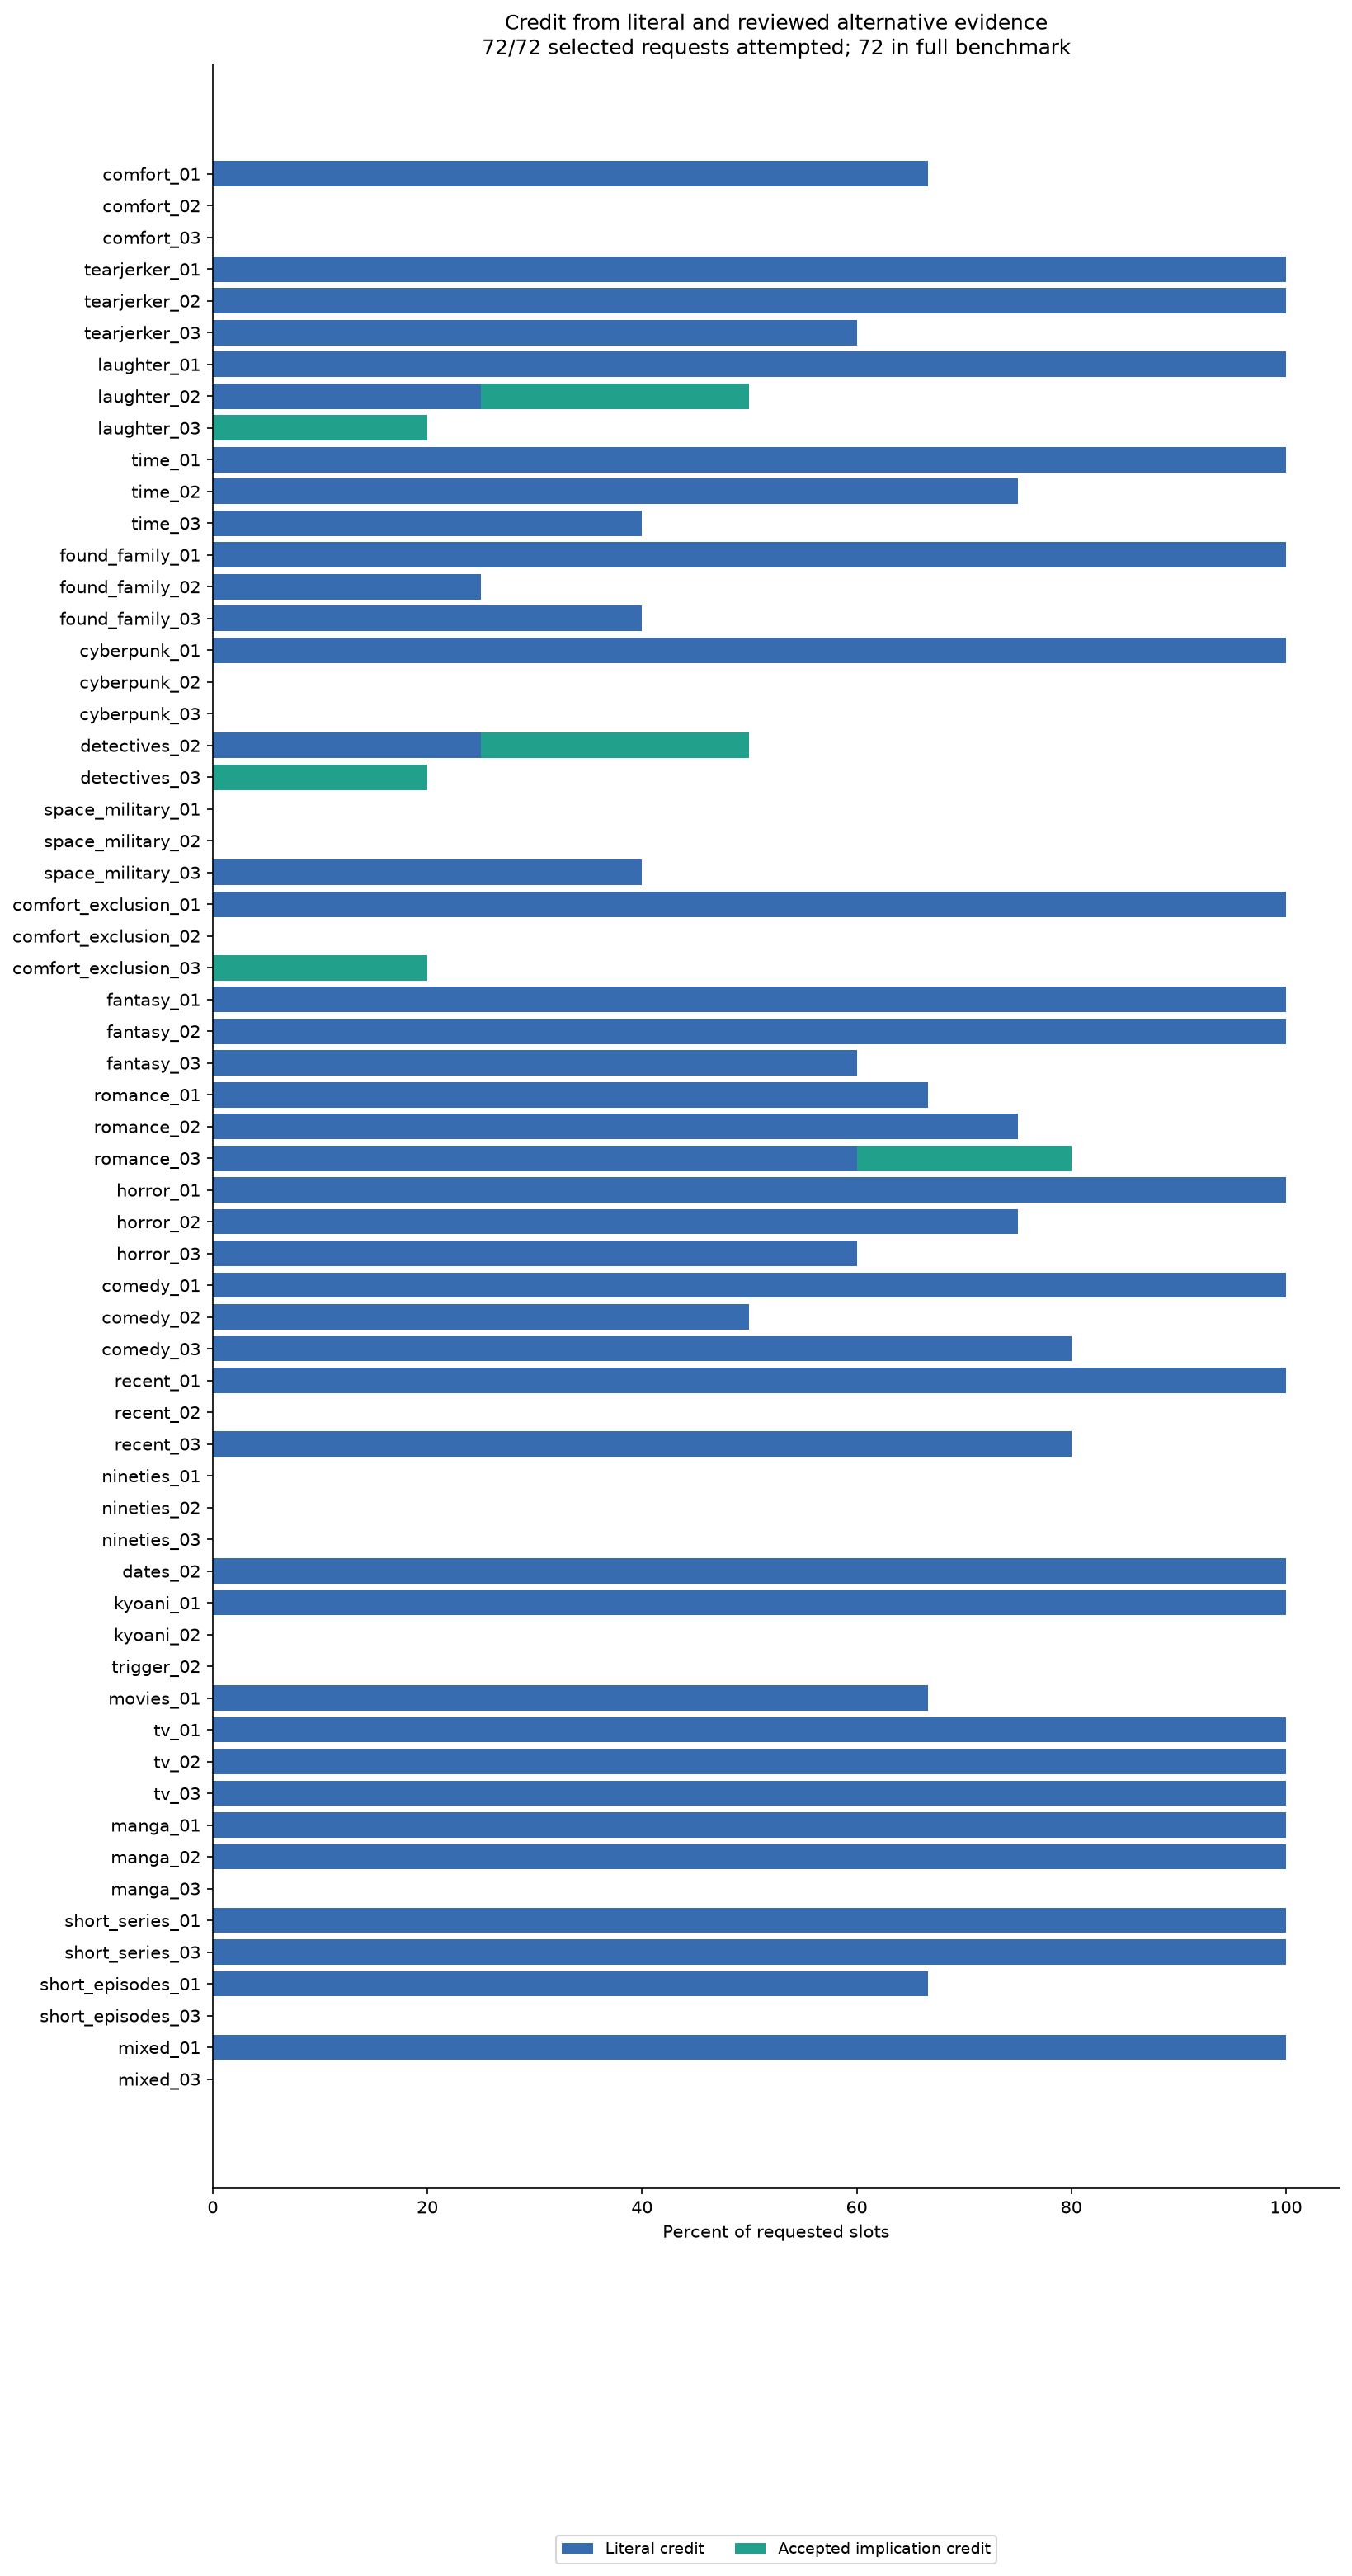

The stacked total equals intent-aware strict P@k. No extra labels are penalized. All-explicit samples may have no implication credit; alternative-path details are saved in the recommendation audit.


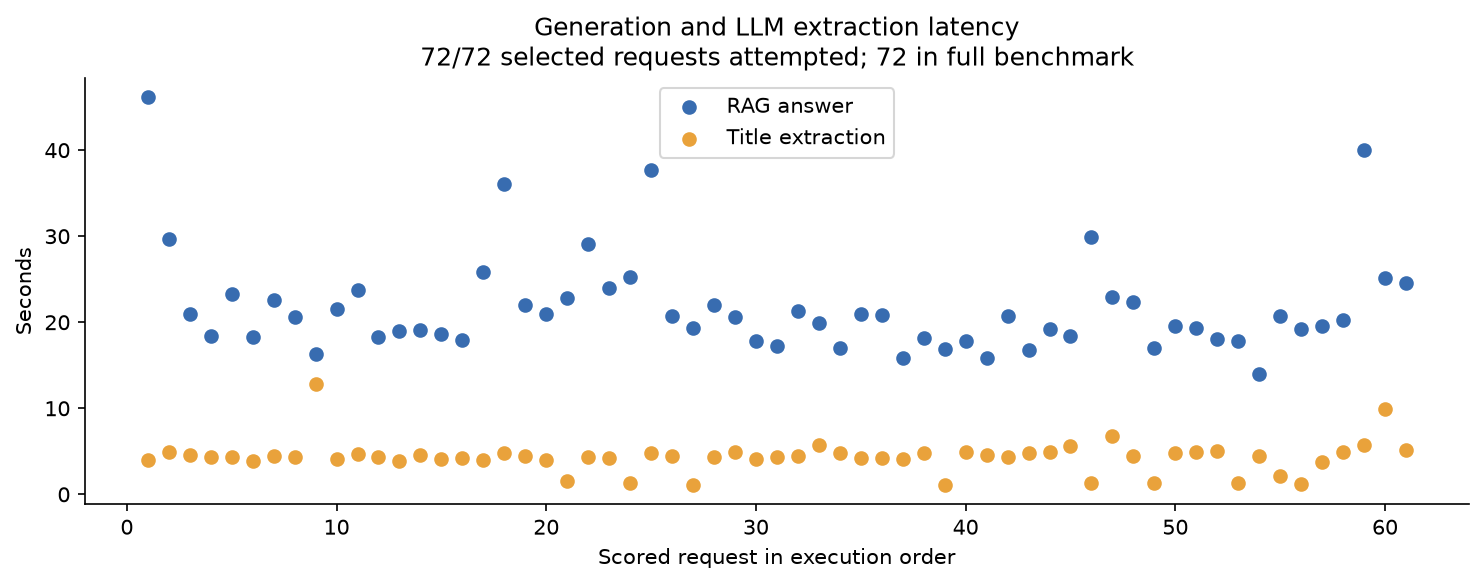

Actual measured timings; cold starts and routing are included. Failures are reported in the outcome chart.
PNG and SVG exports: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\recommendations\results\full_real_v2\charts


In [8]:
if rows:
    show_charts(OUTPUT)

In [9]:
# Change this ID to inspect any saved response and its complete extraction.
INSPECT_ID = rows[0]['question_id'] if rows else None
for row in rows:
    if row['question_id'] == INSPECT_ID:
        print('REQUEST:', row['question'])
        print('EXPECTED CONSTRAINTS:', json.dumps(row['constraints'], ensure_ascii=False))
        print('STATUS:', row['status'], row['error'])
        print('FINAL ANSWER:\n' + row['answer_text'])
        print('LLM EXTRACTION:', json.dumps(row['extraction'], indent=2, ensure_ascii=False))
        break
failures = [{k: r[k] for k in ('question_id', 'status', 'error')} for r in rows
            if r['status'] in {'needs_review', 'extraction_error', 'model_error'}]
if failures:
    display(pd.DataFrame(failures))

REQUEST: Can you recommend three iyashikei anime for winding down?
EXPECTED CONSTRAINTS: [{"field": "tags", "op": "any", "value": ["Iyashikei"], "alternatives": [{"reason": "Gentle everyday-life viewing can be supported by Slice of Life plus domestic/rural/cute-girl daily-life themes, with no strong tragic theme. Slice of Life alone is insufficient.", "constraints": [{"field": "genres", "op": "any", "value": ["Slice of Life"]}, {"field": "tags", "op": "any", "value": ["Cute Girls Doing Cute Things", "Family Life", "Rural"]}, {"field": "tags", "op": "none", "value": ["Tragedy"]}]}]}]
STATUS: scored 
FINAL ANSWER:
Catalog matches — Iyashikei. Ranked by your stated preferences; mood and tone are approximate matches.

1. **Frieren: Beyond Journey’s End** — The adventure is over but life goes on for an elf mage just beginning to learn what living is all about. Elf mage Frieren and her courageous fellow adventurers have defeated the Demon King and brought peace to the land. But Frieren will 

,question_id,status,error
0,detectives_01,needs_review,
1,dates_01,model_error,RuntimeError: No supported recommendations wer...
2,dates_03,model_error,RuntimeError: No supported recommendations wer...
3,kyoani_03,model_error,RuntimeError: No supported recommendations wer...
4,trigger_01,model_error,RuntimeError: No supported recommendations wer...
5,trigger_03,model_error,RuntimeError: No supported recommendations wer...
6,movies_02,model_error,ValueError: Mention must be supported by the u...
7,movies_03,model_error,ValueError: Mention must be supported by the u...
8,short_series_02,model_error,ValueError: Mention must be supported by the u...
9,short_episodes_02,model_error,ValueError: Mention must be supported by the u...


## Interpretation and limits

This benchmark measures adherence to the stated catalog constraints, not whether a
recommendation is enjoyable. Mood-to-tag mappings are human-authored proxies. Tag ranks
reflect the imported community snapshot, not probabilities. Absent tags are zero
positive evidence and do not prove a theme is absent. Titles and season variants can
share aliases; ambiguous matches receive zero credit and remain visible for review.
Studio aliases are fixed through annotation rather than guessed at scoring time.

The prompts are small, synthetic, and in English; genre and tag requests dominate.
Explicit versus indirect comparisons also differ in requested count (3 versus 4/5),
so they are descriptive breakdowns rather than a controlled causal experiment.
The benchmark contains no personalization, real traffic sampling, conversational memory,
or full-franchise runtime evaluation. The extraction model can omit or misidentify
titles; review saved answer/extraction pairs, and use a stronger independent extractor
when available. Report sample sizes and scoring coverage with every quality score.

See `data/evaluation/recommendations/README.md` for file formats, metric formulas,
reproduction commands, and frozen-reference provenance.